# Customer Purchase Prediction using Logistic Regression

## 1. Create Dataset

In [33]:
import pandas as pd

df = pd.DataFrame({
    "Age": [22, 25, 28, 30, 32, 35, 38, 40, 42, 45, 48, 50],
    "Annual_Income": [25000, 30000, 35000, 40000, 45000, 50000,
                      55000, 60000, 65000, 70000, 75000, 80000],
    "Website_Time": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65],
    "Previous_Purchases": [0, 1, 1, 2, 2, 3, 3, 4, 4, 5, 6, 7],
    "Purchased": [0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
})

print(df)

    Age  Annual_Income  Website_Time  Previous_Purchases  Purchased
0    22          25000            10                   0          0
1    25          30000            15                   1          0
2    28          35000            20                   1          0
3    30          40000            25                   2          0
4    32          45000            30                   2          1
5    35          50000            35                   3          1
6    38          55000            40                   3          1
7    40          60000            45                   4          1
8    42          65000            50                   4          1
9    45          70000            55                   5          1
10   48          75000            60                   6          1
11   50          80000            65                   7          1


## 2. Understand the Dataset

In [34]:
print(df.shape)
print(df.info())
print(df.describe())

(12, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 12 non-null     int64
 1   Annual_Income       12 non-null     int64
 2   Website_Time        12 non-null     int64
 3   Previous_Purchases  12 non-null     int64
 4   Purchased           12 non-null     int64
dtypes: int64(5)
memory usage: 612.0 bytes
None
             Age  Annual_Income  Website_Time  Previous_Purchases  Purchased
count  12.000000      12.000000     12.000000           12.000000  12.000000
mean   36.250000   52500.000000     37.500000            3.166667   0.666667
std     9.096703   18027.756377     18.027756            2.124889   0.492366
min    22.000000   25000.000000     10.000000            0.000000   0.000000
25%    29.500000   38750.000000     23.750000            1.750000   0.000000
50%    36.500000   52500.000000     37.500000      

## 3. Exploratory Data Analysis

In [35]:
print(df["Purchased"].value_counts())

Purchased
1    8
0    4
Name: count, dtype: int64


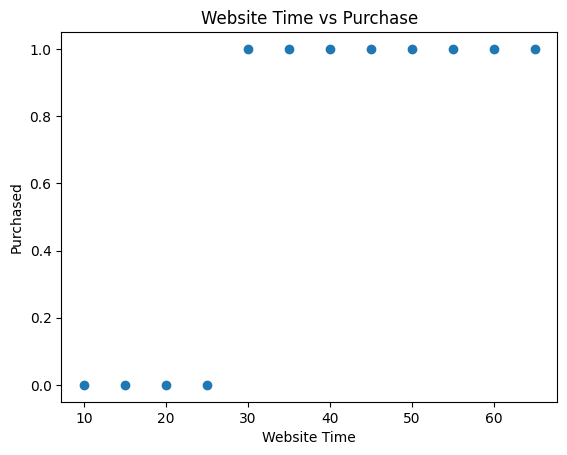

In [36]:
import matplotlib.pyplot as plt

plt.scatter(df["Website_Time"], df["Purchased"])

plt.xlabel("Website Time")
plt.ylabel("Purchased")
plt.title("Website Time vs Purchase")

plt.show()

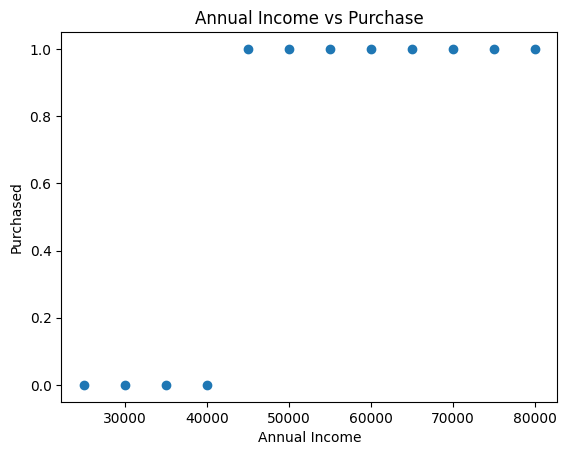

In [37]:
plt.scatter(df["Annual_Income"], df["Purchased"])

plt.xlabel("Annual Income")
plt.ylabel("Purchased")
plt.title("Annual Income vs Purchase")

plt.show()

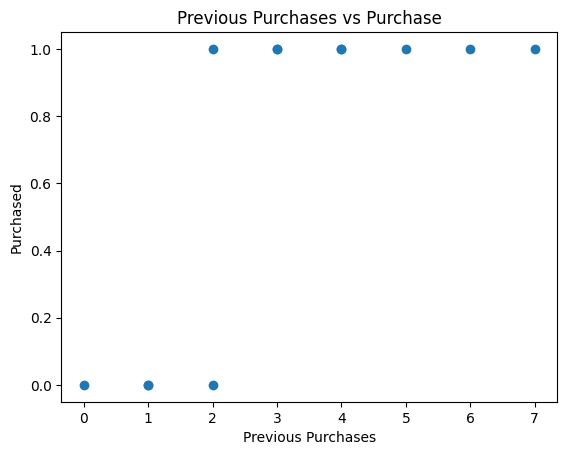

In [38]:
plt.scatter(df["Previous_Purchases"], df["Purchased"])

plt.xlabel("Previous Purchases")
plt.ylabel("Purchased")
plt.title("Previous Purchases vs Purchase")

plt.show()

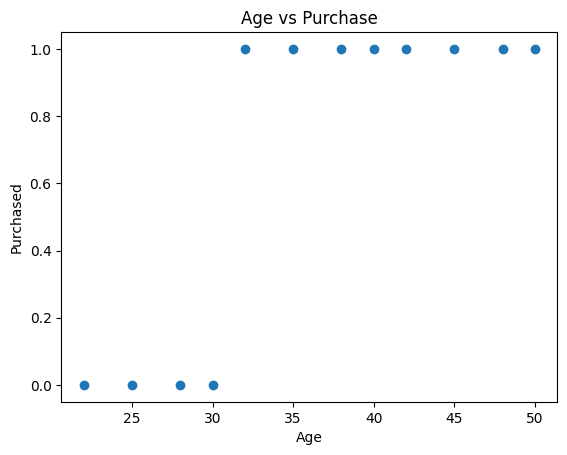

In [39]:
plt.scatter(df["Age"], df["Purchased"])

plt.xlabel("Age")
plt.ylabel("Purchased")
plt.title("Age vs Purchase")

plt.show()

## 4. Select Features and Target

In [40]:
X = df[["Age", "Annual_Income", "Website_Time", "Previous_Purchases"]]
y = df["Purchased"]
print(X)
print(y)

    Age  Annual_Income  Website_Time  Previous_Purchases
0    22          25000            10                   0
1    25          30000            15                   1
2    28          35000            20                   1
3    30          40000            25                   2
4    32          45000            30                   2
5    35          50000            35                   3
6    38          55000            40                   3
7    40          60000            45                   4
8    42          65000            50                   4
9    45          70000            55                   5
10   48          75000            60                   6
11   50          80000            65                   7
0     0
1     0
2     0
3     0
4     1
5     1
6     1
7     1
8     1
9     1
10    1
11    1
Name: Purchased, dtype: int64


## 5. Train-Test Split

In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print(X_train)
print(X_test)
print(y_train)
print(y_test)

    Age  Annual_Income  Website_Time  Previous_Purchases
8    42          65000            50                   4
5    35          50000            35                   3
2    28          35000            20                   1
1    25          30000            15                   1
11   50          80000            65                   7
4    32          45000            30                   2
7    40          60000            45                   4
3    30          40000            25                   2
6    38          55000            40                   3
    Age  Annual_Income  Website_Time  Previous_Purchases
10   48          75000            60                   6
9    45          70000            55                   5
0    22          25000            10                   0
8     1
5     1
2     0
1     0
11    1
4     1
7     1
3     0
6     1
Name: Purchased, dtype: int64
10    1
9     1
0     0
Name: Purchased, dtype: int64


## 6. Train Logistic Regression Model

In [42]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

##7. Make Predictions

In [43]:
y_pred = model.predict(X_test)

print(y_pred)

[1 1 0]


##8. Prediction Probabilities

In [44]:
y_probability = model.predict_proba(X_test)

print(y_probability)

[[0.0000000e+00 1.0000000e+00]
 [0.0000000e+00 1.0000000e+00]
 [1.0000000e+00 2.1527622e-42]]


## 9. Model Evaluation

### Accuracy

In [45]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 1.0


### Confusion Matrix

In [46]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1 0]
 [0 2]]


### Precision

In [47]:
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 1.0


### Recall

In [48]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 1.0


### F1 Score

In [49]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred)

print("F1 Score:", f1)

F1 Score: 1.0


## 10. Predict New Customer

In [50]:
new_customer = pd.DataFrame({
    "Age": [35],
    "Annual_Income": [55000],
    "Website_Time": [42],
    "Previous_Purchases": [3]
})

print(new_customer)

   Age  Annual_Income  Website_Time  Previous_Purchases
0   35          55000            42                   3


In [51]:
prediction = model.predict(new_customer)

print("Prediction:", prediction)

probability = model.predict_proba(new_customer)

print("Probability:", probability)

Prediction: [1]
Probability: [[0. 1.]]


## 11. Conclusion

In this project, we built a Logistic Regression model to predict whether a customer will purchase a product.

The model used four features:
- Age
- Annual Income
- Website Time
- Previous Purchases

The target variable was Purchased:
- 0 = No Purchase
- 1 = Purchase

We split the dataset into training and testing data and trained a Logistic Regression model.

The model was evaluated using:
- Accuracy
- Confusion Matrix
- Precision
- Recall
- F1 Score

Finally, we used the trained model to predict whether a new customer would purchase a product and obtained the prediction probability.